# IoT SOC anomaly lab: walkthrough

This notebook runs the offline experiment step by step:
**simulate gateway events → 5-minute behaviour windows → per-device baselines → detectors → calibration → evaluation → alerts with reasons.**

Run the cells in order. Each step takes a few seconds; training takes about 15 seconds.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # make the iotsoc package importable
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)

from iotsoc import simulate as sim, features, pipeline, evaluate
from iotsoc.wazuh_io import normalize

## 1. Simulate six days of gateway events
Day 0 warm-up, days 1–3 training, day 4 calibration, day 5 test (7 attacks + 3 benign surprises). The ground truth (`incidents`) is kept apart from the events.

In [2]:
events, incidents = sim.simulate(seed=7)
frame = normalize(events)
print(len(frame), "events")
frame["kind"].value_counts()

112894 events


kind
mqtt_publish      76416
flow              26691
dns_query          8707
device_auth         485
mqtt_connect        305
mqtt_subscribe      264
config_change        21
fw_update             5
Name: count, dtype: int64

In [3]:
frame[frame["device_id"] == "cam-04"].head(8)

,ts,kind,device_id,device_type,device_ip,outcome,account,service,src_ip,client_id,reason,topic,bytes,dst_ip,dst_port,proto,dst_zone,allowlisted,bytes_out,bytes_in,qname,fw_version,fw_source,fw_signed,setting
56,2026-09-14 00:04:53.997532129+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,10.20.9.10,554.0,tcp,internal,yes,37481942.0,103245.0,None,None,None,None,None
80,2026-09-14 00:06:21.549689054+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,198.51.100.15,443.0,tcp,external,None,11311.0,653.0,None,None,None,None,None
118,2026-09-14 00:09:49.485000372+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,10.20.9.10,554.0,tcp,internal,yes,33118269.0,222945.0,None,None,None,None,None
182,2026-09-14 00:15:01.946640015+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,10.20.9.10,554.0,tcp,internal,yes,36437516.0,250132.0,None,None,None,None,None
201,2026-09-14 00:16:36.543104410+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,198.51.100.12,443.0,tcp,external,None,19344.0,1856.0,None,None,None,None,None
223,2026-09-14 00:18:48.275578260+00:00,dns_query,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,None,NaN,None,None,None,NaN,NaN,pool.ntp.example,None,None,None,None
224,2026-09-14 00:18:48.375578165+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,192.0.2.126,123.0,udp,external,None,76.0,76.0,None,None,None,None,None
237,2026-09-14 00:19:54.135659456+00:00,flow,cam-04,camera,10.20.2.14,None,None,None,None,None,None,None,NaN,10.20.9.10,554.0,tcp,internal,yes,38571110.0,228312.0,None,None,None,None,None


In [4]:
inc = sim.incidents_frame(incidents)
inc.drop_duplicates("incident_id")[["incident_id", "category", "scenario", "device_id", "start", "end", "mitre", "signature_rule"]]

,incident_id,category,scenario,device_id,start,end,mitre,signature_rule
0,A-01,attack,telnet_bruteforce,cam-02,2026-09-19 02:10:00+00:00,2026-09-19 02:55:00+00:00,T1110.001,100602
1,A-02,attack,rogue_firmware,lock-02,2026-09-19 03:30:00+00:00,2026-09-19 03:40:00+00:00,T1542.001,100606
2,A-03,attack,lowslow_bruteforce,hvac-03,2026-09-19 09:00:00+00:00,2026-09-19 13:00:00+00:00,T1110.001,none
3,B-04,benign,maintenance,hvac-01,2026-09-19 10:00:00+00:00,2026-09-19 10:45:00+00:00,-,100603
4,A-05,attack,mqtt_recon,sens-07,2026-09-19 11:20:00+00:00,2026-09-19 11:35:00+00:00,"T1110.001, T1040",100604
5,B-06,benign,firmware_rollout,cam-01,2026-09-19 14:00:00+00:00,2026-09-19 14:30:00+00:00,-,100605
9,A-07,attack,exfiltration,cam-04,2026-09-19 15:10:00+00:00,2026-09-19 15:45:00+00:00,T1048,none
10,B-08,benign,broker_restart,sens-01,2026-09-19 16:30:00+00:00,2026-09-19 16:35:00+00:00,-,none
30,A-09,attack,c2_beaconing,sens-03,2026-09-19 17:00:00+00:00,2026-09-19 22:00:00+00:00,"T1071.001, T1568.002",none
31,A-10,attack,lateral_scan,hvac-02,2026-09-19 20:15:00+00:00,2026-09-19 20:30:00+00:00,T1046,100608


## 2. Behaviour windows
One row per device per 5 minutes, including idle windows. Features count what the device did and how much of it was new.

In [5]:
split = pipeline.Split.by_days(sim.DEFAULT_START)
devices = pipeline.device_map()
windows, memory = features.window_features(frame, devices, split.start, split.end)
print(windows.shape)
windows[windows["device_id"] == "cam-04"].iloc[300:306][["window_start", "period", "ext_flows", "ext_bytes_out", "int_bytes_out", "new_dst", "dns_q"]]

(34560, 30)


,window_start,period,ext_flows,ext_bytes_out,int_bytes_out,new_dst,dns_q
6003,2026-09-15 01:00:00+00:00,night,0.0,0.0,0.0,0.0,1.0
6023,2026-09-15 01:05:00+00:00,night,1.0,39883.0,33061064.0,0.0,0.0
6043,2026-09-15 01:10:00+00:00,night,0.0,0.0,78147589.0,0.0,0.0
6063,2026-09-15 01:15:00+00:00,night,2.0,25577.0,0.0,0.0,1.0
6083,2026-09-15 01:20:00+00:00,night,0.0,0.0,64618113.0,0.0,0.0
6103,2026-09-15 01:25:00+00:00,night,1.0,35052.0,35315240.0,0.0,1.0


## 3. Train on normal days, set thresholds on a separate normal day
No labels are used here.

In [6]:
bundle = pipeline.train_bundle(windows, memory, split, devices, target_fpr=0.002)
bundle.suite.thresholds

{'iforest_raw': 0.6544069464258303,
 'iforest': 0.6705938674853011,
 'lof': 16.15935017950678,
 'autoencoder': 0.08049382743325455}

## 4. Score the test day, then (only now) attach the ground truth

In [7]:
test = split.part(windows, "test")
scored = pipeline.score_windows(bundle, test)
labelled = evaluate.label_windows(scored, inc)
results = evaluate.evaluate(labelled, inc)
results["summary"][["name", "precision", "recall", "pr_auc", "attacks_detected", "median_minutes_to_detect", "false_incidents_per_day"]].round(3)

,name,precision,recall,pr_auc,attacks_detected,median_minutes_to_detect,false_incidents_per_day
0,Signature rules (Wazuh-style),1.000,0.083,NaN,4,5.0,0.0
1,"Isolation Forest, raw features",0.429,0.068,0.139,5,10.0,7.0
2,Isolation Forest + device baselines,0.375,0.045,0.236,3,35.0,6.0
3,LOF + device baselines,0.567,0.129,0.560,5,10.0,2.0
4,Autoencoder + device baselines,0.594,0.977,0.684,7,5.0,7.0
5,Ensemble (2 of 3 agree),0.613,0.144,0.670,5,10.0,1.0
6,Hybrid: rules OR ML policy,0.594,0.977,0.715,7,5.0,7.0


In [8]:
evaluate.coverage_matrix(results["coverage"])

detector,rules,iforest_raw,iforest,lof,autoencoder,ensemble,hybrid
scenario,,,,,,,
c2_beaconing,missed,50 min,50 min,50 min,5 min,50 min,5 min
exfiltration,missed,10 min,20 min,10 min,5 min,10 min,5 min
lateral_scan,5 min,10 min,missed,10 min,5 min,10 min,5 min
lowslow_bruteforce,missed,missed,missed,missed,10 min,missed,10 min
mqtt_recon,5 min,missed,missed,missed,5 min,missed,5 min
rogue_firmware,5 min,5 min,missed,5 min,5 min,5 min,5 min
telnet_bruteforce,5 min,35 min,35 min,35 min,5 min,35 min,5 min


In [9]:
results["triage"]

,severity,alert_windows,attack_windows,benign_event_windows,false_incidents_per_day
0,high,40,28,6,1.0
1,medium,177,101,25,6.0
2,rule only,0,0,0,NaN


## 5. What an analyst sees
The first alerted window on each attacked device, with the plain-language reasons the scorer sends to Wazuh.

In [10]:
alerts = labelled[labelled["alert_hybrid"]]
first = alerts.sort_values("window_start").groupby("device_id").head(1)
first[["window_start", "device_id", "severity", "votes", "attack_scenario", "benign_scenario", "reasons"]]

,window_start,device_id,severity,votes,attack_scenario,benign_scenario,reasons
20,2026-09-19 00:05:00+00:00,cam-01,medium,1,,,small deviations only: MQTT connections 1 (usual 0); failed device logins 1 (usual 0-1)
521,2026-09-19 02:10:00+00:00,cam-02,high,1,telnet_bruteforce,,failed device logins 61 (usual 0); failed logins in the last hour 61 (usual 0-1)
547,2026-09-19 02:15:00+00:00,lock-01,medium,1,,,small deviations only: bytes sent to the internet 2.6 kB (usual 0 B-2.9 kB); bytes received 876 B (usual 0 B-1.9 kB)
848,2026-09-19 03:30:00+00:00,lock-02,high,2,rogue_firmware,,bytes received 4.4 MB (usual 0 B-1.9 kB)
2066,2026-09-19 08:35:00+00:00,hvac-03,medium,1,,,small deviations only: bytes sent to the internet 5.5 kB (usual 0 B-8.7 kB); configuration changes 2 (usual 0)
2404,2026-09-19 10:00:00+00:00,hvac-01,medium,1,,maintenance,small deviations only: failed device logins 1 (usual 0); successful device logins 1 (usual 0)
2736,2026-09-19 11:20:00+00:00,sens-07,high,1,mqtt_recon,,failed MQTT connections 6 (usual 0); MQTT subscriptions 3 (usual 0)
3422,2026-09-19 14:15:00+00:00,cam-03,high,3,,firmware_rollout,bytes received 87.9 MB (usual 101.7 kB-298.8 kB)
3443,2026-09-19 14:20:00+00:00,cam-04,high,2,,firmware_rollout,bytes received 102.9 MB (usual 0 B-507.0 kB); DNS lookups 3 (usual 0-1)
3979,2026-09-19 16:30:00+00:00,sens-10,medium,1,,broker_restart,small deviations only: bytes sent to the internet 5.9 kB (usual 0 B-5.9 kB); internet connections 2 (usual 0-2)


## 6. One attack up close: exfiltration from cam-04

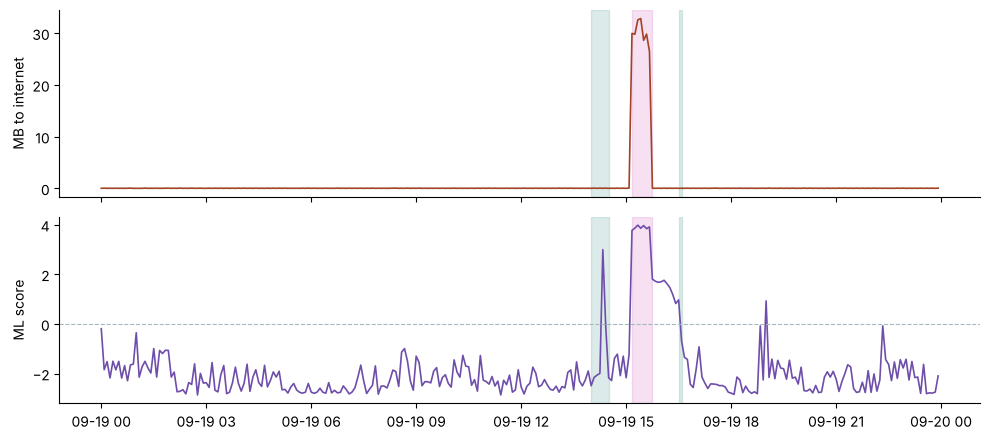

In [11]:
import matplotlib.pyplot as plt
cam = labelled[labelled["device_id"] == "cam-04"].set_index("window_start")
fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
axes[0].plot(cam.index, cam["ext_bytes_out"] / 1e6, color="#a14324", lw=1.2)
axes[0].set_ylabel("MB to internet")
axes[1].plot(cam.index, cam["score_ml"], color="#6e4eaa", lw=1.2)
axes[1].axhline(0, color="#a4b9c0", ls="--", lw=0.8)
axes[1].set_ylabel("ML score")
for ax in axes:
    for _, r in inc[inc["device_id"] == "cam-04"].iterrows():
        ax.axvspan(r["start"], r["end"], color="#d666c2" if r["category"] == "attack" else "#509f95", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## Try it yourself
1. Change `target_fpr` in step 3 to `0.0005` and `0.01`. What happens to attacks found and false incidents per day?
2. Look at the broker restart at 16:30: how many devices raise an alert, and how would you group them into one incident?
3. Remove the 1-hour rolling features from `features.ML_FEATURES` (restart the kernel after editing) and check whether the low-and-slow brute force is still found.